[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/attention-explained/blob/main/notebooks/11_tiny_transformer.ipynb)

# 11 · A Tiny Working Transformer, Trained Live

*Attention, Explained · Hamza Hentabli, Ph.D. · ~35 min*

Time to put every piece together. We build a complete (tiny) Transformer **from scratch** in PyTorch, train it live on a CPU to **sort lists of digits**, plot the real training curves, re-implement its forward pass in **pure NumPy** to prove there is no magic, and look at the attention patterns it learned.

**Learning objectives.** By the end of this notebook you will be able to:

- build a complete Transformer encoder from scratch (attention, multi-head, blocks, read-out)
- **train** it on a toy algorithmic task and plot real **loss and accuracy curves**
- re-implement the forward pass in **NumPy** and verify it matches PyTorch
- inspect the **learned attention** and connect it to the algorithm the model found

In [1]:
# Setup: on Google Colab this installs anything missing and clones the repo so the
# shared `attn_utils` helper is available. Running locally, install requirements.txt
# once and this cell just locates the files. No notebook needs the network after this.
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
OFFLINE = os.environ.get("ATTN_OFFLINE", "0") == "1"   # CI sets this; everything is computed locally
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "numpy", "torch", "matplotlib", "scikit-learn"], check=True)
    if not os.path.isdir("attention-explained"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/attention-explained.git"], check=True)
    ROOT = "attention-explained"
else:
    ROOT = ".." if os.path.exists("../attn_utils.py") else "."
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

import numpy as np
import matplotlib.pyplot as plt
import attn_utils as au

au.set_docs_dir(os.path.join(ROOT, "docs"))
au.set_seed(0)
np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print("Colab:", IN_COLAB, "| offline:", OFFLINE, "| numpy", np.__version__)


Colab: False | offline: True | numpy 2.4.6


## 1. The task: sort a list of digits

Input: 8 random digits. Output, at each position: the digit that belongs there once the list is **sorted**.

```
input : 7 2 9 2 0 5 1 8
output: 0 1 2 2 5 7 8 9
```

Why sorting? It is impossible without attention: to know what belongs at output position 3, a token must **compare itself with every other token**. No single token holds the answer — it has to be gathered from the whole sequence. It is also tiny, so the model trains on a CPU in seconds, and we can check every answer.

In [2]:
import time
import torch
import torch.nn as nn
import torch.nn.functional as F
torch.set_num_threads(4)

VOCAB, L = 10, 8
def sort_batch(B, generator=None):
    x = torch.randint(0, VOCAB, (B, L), generator=generator)
    return x, x.sort(dim=1).values

x, y = sort_batch(3)
for a, b in zip(x, y):
    print("input", a.tolist(), "-> target", b.tolist())

input [4, 9, 3, 0, 3, 9, 7, 3] -> target [0, 3, 3, 3, 4, 7, 9, 9]
input [7, 3, 1, 6, 6, 9, 8, 6] -> target [1, 3, 6, 6, 6, 7, 8, 9]
input [6, 8, 4, 3, 6, 9, 1, 4] -> target [1, 3, 4, 4, 6, 6, 8, 9]


## 2. A Transformer from scratch in PyTorch

Every piece is written out — no `nn.MultiheadAttention`, no `nn.Transformer`. It is exactly the architecture of Notebooks 04–09: embeddings + learned positions → 2 **pre-norm** blocks (multi-head self-attention + feed-forward, both with residuals) → a final LayerNorm and a linear read-out. No causal mask: this is an **encoder**, every token may look at every other token.

In [3]:
class SelfAttention(nn.Module):
    def __init__(self, d_model, n_heads):
        super().__init__()
        self.h, self.dh = n_heads, d_model // n_heads
        self.Wq = nn.Linear(d_model, d_model)
        self.Wk = nn.Linear(d_model, d_model)
        self.Wv = nn.Linear(d_model, d_model)
        self.Wo = nn.Linear(d_model, d_model)
    def forward(self, x):
        B, T, D = x.shape
        split = lambda t: t.view(B, T, self.h, self.dh).transpose(1, 2)       # (B, h, T, dh)
        q, k, v = split(self.Wq(x)), split(self.Wk(x)), split(self.Wv(x))
        weights = (q @ k.transpose(-2, -1) / self.dh ** 0.5).softmax(dim=-1)  # (B, h, T, T)
        z = (weights @ v).transpose(1, 2).reshape(B, T, D)                    # concat heads
        return self.Wo(z), weights

class Block(nn.Module):
    def __init__(self, d_model, n_heads):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.attn = SelfAttention(d_model, n_heads)
        self.ff = nn.Sequential(nn.Linear(d_model, 4 * d_model), nn.ReLU(), nn.Linear(4 * d_model, d_model))
    def forward(self, x):
        a, w = self.attn(self.ln1(x))
        x = x + a                       # residual 1
        x = x + self.ff(self.ln2(x))    # residual 2
        return x, w

class TinyTransformer(nn.Module):
    def __init__(self, d_model=64, n_heads=2, n_layers=2):
        super().__init__()
        self.tok = nn.Embedding(VOCAB, d_model)
        self.pos = nn.Parameter(torch.randn(L, d_model) * 0.1)
        self.blocks = nn.ModuleList([Block(d_model, n_heads) for _ in range(n_layers)])
        self.ln_f = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, VOCAB)
    def forward(self, x):
        h = self.tok(x) + self.pos
        all_w = []
        for blk in self.blocks:
            h, w = blk(h)
            all_w.append(w)
        return self.head(self.ln_f(h)), all_w

au.set_seed(0)
model = TinyTransformer()
print(model)
print(f"\ntrainable parameters: {sum(p.numel() for p in model.parameters()):,}")

TinyTransformer(
  (tok): Embedding(10, 64)
  (blocks): ModuleList(
    (0-1): 2 x Block(
      (ln1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
      (ln2): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
      (attn): SelfAttention(
        (Wq): Linear(in_features=64, out_features=64, bias=True)
        (Wk): Linear(in_features=64, out_features=64, bias=True)
        (Wv): Linear(in_features=64, out_features=64, bias=True)
        (Wo): Linear(in_features=64, out_features=64, bias=True)
      )
      (ff): Sequential(
        (0): Linear(in_features=64, out_features=256, bias=True)
        (1): ReLU()
        (2): Linear(in_features=256, out_features=64, bias=True)
      )
    )
  )
  (ln_f): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
  (head): Linear(in_features=64, out_features=10, bias=True)
)

trainable parameters: 101,898


## 3. Train it live

Adam, batch 128, 1,500 steps of fresh random lists, with two standard stabilisers used to train real Transformers: **gradient clipping** (cap the gradient norm at 1) and a **cosine learning-rate decay** (start at 1e-3, glide to ~0) (so the model never sees the same batch twice — it cannot memorise, it has to learn the algorithm). Every 50 steps we also measure accuracy on a fixed **held-out** set of 2,000 lists.

In [4]:
g = torch.Generator().manual_seed(1234)
x_val, y_val = sort_batch(2000, generator=g)          # fixed held-out set

def evaluate(model):
    model.eval()
    with torch.no_grad():
        logits, _ = model(x_val)
        loss = F.cross_entropy(logits.reshape(-1, VOCAB), y_val.reshape(-1)).item()
        pred = logits.argmax(-1)
        tok_acc = (pred == y_val).float().mean().item()
        seq_acc = (pred == y_val).all(dim=1).float().mean().item()
    model.train()
    return loss, tok_acc, seq_acc

au.set_seed(0)
model = TinyTransformer()
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
STEPS = 1500
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=STEPS)
train_loss, val_log = [], []
t0 = time.time()
for step in range(1, STEPS + 1):
    x, y = sort_batch(128)
    logits, _ = model(x)
    loss = F.cross_entropy(logits.reshape(-1, VOCAB), y.reshape(-1))
    opt.zero_grad(); loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    opt.step(); sched.step()
    train_loss.append(loss.item())
    if step % 50 == 0 or step == 1:
        val_log.append((step, *evaluate(model)))
    if step % 250 == 0:
        s, vl, ta, sa = val_log[-1]
        print(f"step {step:5d} | train loss {loss.item():.4f} | held-out loss {vl:.4f} | token acc {ta:.4f} | whole-list acc {sa:.4f}")
print(f"\ntraining time: {time.time() - t0:.1f} s on CPU")
final_loss, final_tok, final_seq = evaluate(model)
print(f"FINAL held-out: loss {final_loss:.4f}, token accuracy {final_tok:.4f}, whole-list accuracy {final_seq:.4f}")

step   250 | train loss 0.0157 | held-out loss 0.0259 | token acc 0.9952 | whole-list acc 0.9630


step   500 | train loss 0.0093 | held-out loss 0.0116 | token acc 0.9966 | whole-list acc 0.9730


step   750 | train loss 0.0023 | held-out loss 0.0032 | token acc 0.9992 | whole-list acc 0.9940


step  1000 | train loss 0.0005 | held-out loss 0.0005 | token acc 1.0000 | whole-list acc 1.0000


step  1250 | train loss 0.0004 | held-out loss 0.0004 | token acc 1.0000 | whole-list acc 1.0000


step  1500 | train loss 0.0004 | held-out loss 0.0004 | token acc 1.0000 | whole-list acc 1.0000

training time: 19.3 s on CPU
FINAL held-out: loss 0.0004, token accuracy 1.0000, whole-list accuracy 1.0000


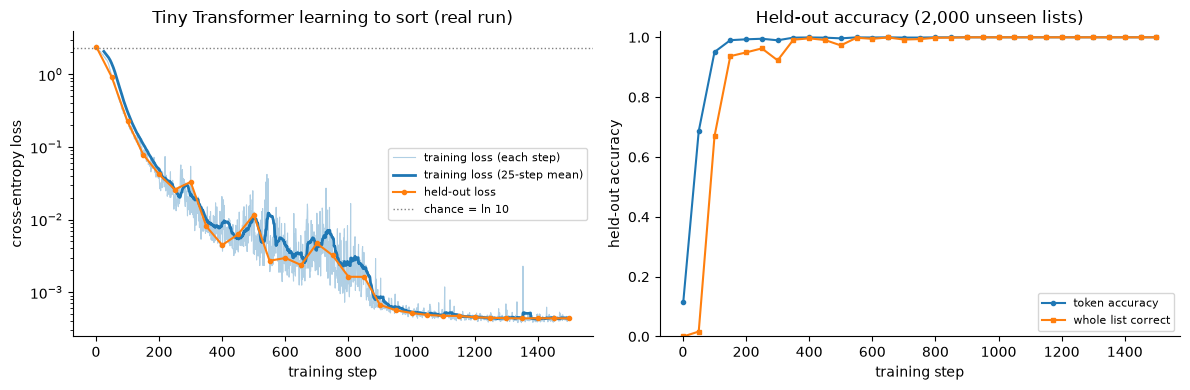

In [5]:
steps_v, vloss, vtok, vseq = map(np.array, zip(*val_log))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(np.arange(1, STEPS + 1), train_loss, color="tab:blue", alpha=0.35, lw=0.8, label="training loss (each step)")
smooth = np.convolve(train_loss, np.ones(25) / 25, mode="valid")
axes[0].plot(np.arange(25, STEPS + 1), smooth, color="tab:blue", lw=2, label="training loss (25-step mean)")
axes[0].plot(steps_v, vloss, "o-", color="tab:orange", ms=3, label="held-out loss")
axes[0].axhline(np.log(VOCAB), color="grey", ls=":", lw=1, label="chance = ln 10")
axes[0].set_yscale("log"); axes[0].set_xlabel("training step"); axes[0].set_ylabel("cross-entropy loss")
axes[0].set_title("Tiny Transformer learning to sort (real run)"); axes[0].legend(fontsize=8)
axes[1].plot(steps_v, vtok, "o-", ms=3, label="token accuracy")
axes[1].plot(steps_v, vseq, "s-", ms=3, label="whole list correct")
axes[1].set_ylim(0, 1.02); axes[1].set_xlabel("training step"); axes[1].set_ylabel("held-out accuracy")
axes[1].set_title("Held-out accuracy (2,000 unseen lists)"); axes[1].legend(fontsize=8)
plt.tight_layout()
au.save_fig(fig, "11_training_loss.png")
plt.show()

The loss falls by more than three orders of magnitude from the chance level ($\ln 10 \approx 2.30$), and the held-out curve tracks the training curve closely: since every batch is freshly sampled, there is nothing to overfit. Small bumps in the curve are normal Adam noise; clipping and the decaying learning rate keep them from derailing training.

## 4. Try it

In [6]:
examples = torch.tensor([[7, 2, 9, 2, 0, 5, 1, 8],
                         [9, 9, 9, 0, 0, 0, 5, 5],
                         [3, 1, 4, 1, 5, 9, 2, 6],
                         [0, 1, 2, 3, 4, 5, 6, 7]])
with torch.no_grad():
    pred = model(examples)[0].argmax(-1)
for a, p in zip(examples, pred):
    ok = "✓" if torch.equal(p, a.sort().values) else "✗"
    print(f"{a.tolist()} -> {p.tolist()}  {ok}")

[7, 2, 9, 2, 0, 5, 1, 8] -> [0, 1, 2, 2, 5, 7, 8, 9]  ✓
[9, 9, 9, 0, 0, 0, 5, 5] -> [0, 0, 0, 5, 5, 9, 9, 9]  ✓
[3, 1, 4, 1, 5, 9, 2, 6] -> [1, 1, 2, 3, 4, 5, 6, 9]  ✓
[0, 1, 2, 3, 4, 5, 6, 7] -> [0, 1, 2, 3, 4, 5, 6, 7]  ✓


## 5. The same model in pure NumPy

Training needs automatic differentiation, which is what PyTorch provides. But the **forward pass** is nothing more than the NumPy operations from Notebooks 04–09. To prove it, we copy the trained weights into NumPy arrays and rebuild the model's prediction with `au.softmax`, matrix multiplies and our own LayerNorm — then check it agrees with PyTorch.

In [7]:
P = {k: v.detach().numpy().astype(np.float64) for k, v in model.state_dict().items()}

def np_layer_norm(x, w, b, eps=1e-5):
    mu, var = x.mean(-1, keepdims=True), x.var(-1, keepdims=True)
    return (x - mu) / np.sqrt(var + eps) * w + b

def np_linear(x, name):
    return x @ P[name + ".weight"].T + P[name + ".bias"]

def np_forward(tokens, n_layers=2, n_heads=2):
    h = P["tok.weight"][tokens] + P["pos"]                    # (T, D)
    T, D = h.shape; dh = D // n_heads
    weights = []
    for i in range(n_layers):
        pre = f"blocks.{i}."
        x = np_layer_norm(h, P[pre + "ln1.weight"], P[pre + "ln1.bias"])
        split = lambda M: M.reshape(T, n_heads, dh).transpose(1, 0, 2)
        q, k, v = (split(np_linear(x, pre + f"attn.W{c}")) for c in "qkv")
        z, w = au.scaled_dot_product_attention(q, k, v)          # Notebook 04's formula, per head
        h = h + np_linear(z.transpose(1, 0, 2).reshape(T, D), pre + "attn.Wo")
        x = np_layer_norm(h, P[pre + "ln2.weight"], P[pre + "ln2.bias"])
        h = h + np_linear(np.maximum(0, np_linear(x, pre + "ff.0")), pre + "ff.2")
        weights.append(w)
    h = np_layer_norm(h, P["ln_f.weight"], P["ln_f.bias"])
    return np_linear(h, "head"), weights

agree, max_diff = 0, 0.0
with torch.no_grad():
    torch_logits = model(x_val[:500])[0].numpy()
for i in range(500):
    np_logits, _ = np_forward(x_val[i].numpy())
    max_diff = max(max_diff, np.abs(np_logits - torch_logits[i]).max())
    agree += np.array_equal(np_logits.argmax(-1), torch_logits[i].argmax(-1))
print(f"NumPy vs PyTorch on 500 held-out lists: identical predictions for {agree}/500, max logit difference {max_diff:.2e}")

NumPy vs PyTorch on 500 held-out lists: identical predictions for 500/500, max logit difference 1.28e-05


## 6. What did the attention learn?

Let's look inside for one input. For sorting, output position $i$ needs *the $i$-th smallest digit*, so in the last layer we expect each position to attend to input tokens **by value**, not by position: if the list is drawn in sorted order, the attention should line up along a (staircase) diagonal.

input : [6, 1, 8, 3, 0, 9, 4, 2]
output: [0, 1, 2, 3, 4, 6, 8, 9]


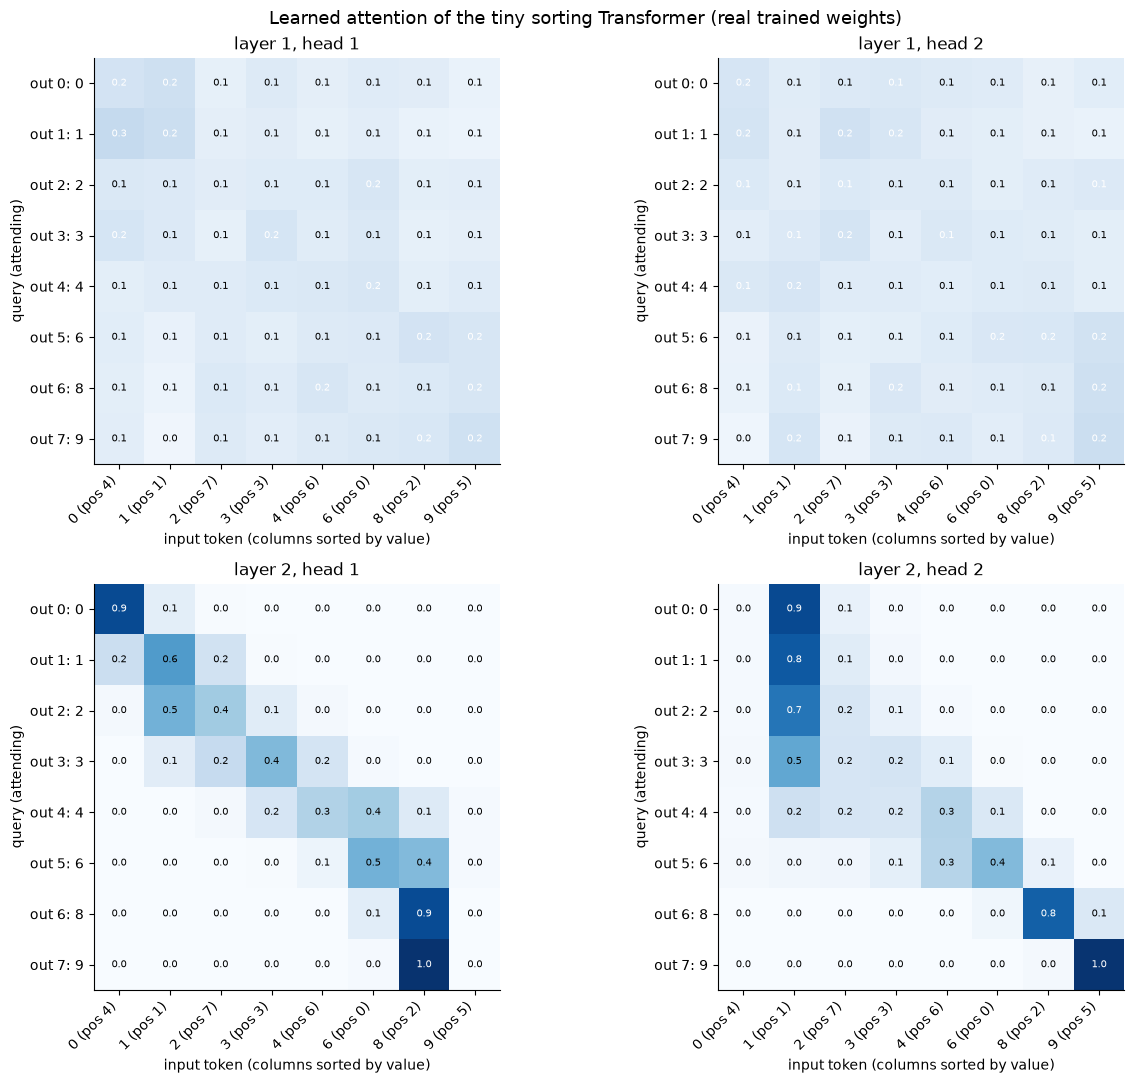

In [8]:
x_demo = torch.tensor([[6, 1, 8, 3, 0, 9, 4, 2]])
with torch.no_grad():
    logits, W = model(x_demo)
inp = x_demo[0].tolist()
outp = logits.argmax(-1)[0].tolist()
print("input :", inp); print("output:", outp)

order = np.argsort(inp, kind="stable")                    # input positions sorted by value
in_labels = [f"{inp[j]} (pos {j})" for j in order]
out_labels = [f"out {i}: {o}" for i, o in enumerate(outp)]
fig, axes = plt.subplots(2, 2, figsize=(13, 11))
for layer in range(2):
    for head in range(2):
        Wh = W[layer][0, head].numpy()[:, order]          # columns re-ordered by input value
        au.plot_attention(Wh, out_labels, in_labels, ax=axes[layer, head], vmax=1, fmt="{:.1f}",
                          title=f"layer {layer + 1}, head {head + 1}")
        axes[layer, head].set_xlabel("input token (columns sorted by value)")
fig.suptitle("Learned attention of the tiny sorting Transformer (real trained weights)", fontsize=13)
plt.tight_layout()
au.save_fig(fig, "11_learned_attention.png")
plt.show()

With the key columns arranged in sorted order, look for heads in the **last layer** whose bright cells fall near the diagonal: output position $i$ is attending to the input token whose value is $i$-th smallest — the model has learned to *retrieve by rank*. Earlier-layer heads often look more spread out: they compute how each token compares with the others (how many digits are smaller), which the last layer then uses to fetch the right value. Your exact patterns depend on the run, but the diagonal structure in at least one late head is the signature of a learned sorting algorithm built entirely from attention.

## Key takeaways

- A complete Transformer is ~60 lines of PyTorch built from pieces you now know.
- It learns a non-trivial algorithm (**sorting**) from examples in seconds on a CPU; the training curves above are from a real run.
- The forward pass is just the NumPy maths of this course — verified to match PyTorch.
- The learned attention is readable: late heads **retrieve tokens by rank**.

### ✏️ Exercise 1

Retrain with `n_layers=1` (keep everything else). What final whole-list accuracy do you get? Is one layer enough?

<details>
<summary><b>Show solution</b></summary>

```python
au.set_seed(0)
m1 = TinyTransformer(n_layers=1); opt1 = torch.optim.Adam(m1.parameters(), lr=1e-3)
for step in range(STEPS):
    x, y = sort_batch(128)
    loss = F.cross_entropy(m1(x)[0].reshape(-1, VOCAB), y.reshape(-1))
    opt1.zero_grad(); loss.backward(); opt1.step()
print(evaluate(m1))
```



</details>

### ✏️ Exercise 2

Change the task to **reversing** the list (`y = x.flip(1)`) and retrain. Plot one attention map — what shape do you expect?

<details>
<summary><b>Show solution</b></summary>

```python
au.set_seed(0)
mr = TinyTransformer(); optr = torch.optim.Adam(mr.parameters(), lr=1e-3)
for step in range(800):
    x = torch.randint(0, VOCAB, (128, L))
    loss = F.cross_entropy(mr(x)[0].reshape(-1, VOCAB), x.flip(1).reshape(-1))
    optr.zero_grad(); loss.backward(); optr.step()
with torch.no_grad():
    _, Wr = mr(x_demo)
au.plot_attention(Wr[-1][0, 0].numpy(), list(range(L)), list(range(L))); plt.show()
```

Reversal is purely positional, so you should find an anti-diagonal (as in Notebook 01).

</details>

### ✏️ Exercise 3

Use `np_forward` to sort the list `[5, 5, 1, 0, 9, 3, 3, 7]` with NumPy only.

<details>
<summary><b>Show solution</b></summary>

```python
lg, _ = np_forward(np.array([5, 5, 1, 0, 9, 3, 3, 7]))
print(lg.argmax(-1))
```



</details>